In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler


df_in=pd.read_csv("../../data/raw/bdd_in_mat_05.csv",header=None)
df_out=pd.read_csv("../../data/raw/bdd_out_mat_05.csv",header=None)

Ts=0.05

# Etape 1 : Analyse des données et redimensionnement 

#### Analyse rapide des données pour voir si y'a pas des Nans, le max le min de l'entrée et de la sortie et fonction pour plot des signaux

In [9]:
def plot_signal(i):
    fig, ax = plt.subplots(figsize=(10, 4))
    t =np.arange(0,2000*Ts,Ts)
    entree=df_in.iloc[i]
    sortie=df_out.iloc[i]
    

    ax.plot(t, entree, label="Entrée")
    ax.plot(t, sortie, label="Sortie")

    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()

In [10]:
print(df_in.shape)
print(df_out.shape)

print(df_in.isna().sum().sum())
print(df_out.isna().sum().sum())

(3000, 2000)
(3000, 2000)
0
0


In [11]:
df_out.min().min()
df_out.max().max()


np.float64(412.925797764055)

### On plot ici les max et min comparés aux max des entrés pour voir les singaux déféctueux.


(array([ 122,  455, 1233, 1677]),)

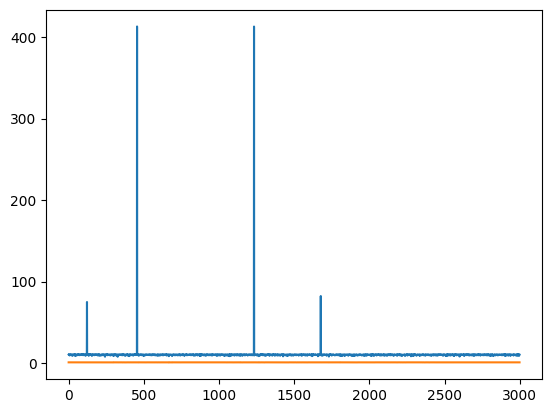

In [12]:
plt.plot(np.arange(0,3000,1),df_out.max(axis=1))
plt.plot(np.arange(0,3000,1),df_in.max(axis=1))

np.where(df_out.max(axis=1)>20)

(array([ 122, 1677]),)

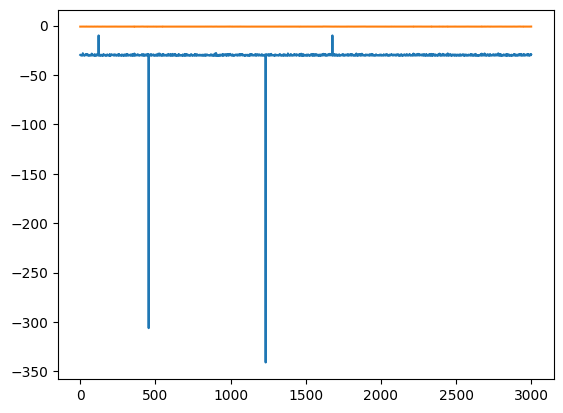

In [13]:
plt.plot(np.arange(0,3000,1),df_out.min(axis=1))
plt.plot(np.arange(0,3000,1),df_in.min(axis=1))

np.where(df_out.min(axis=1)>-20)

#### On supprime les outliers des données et ensuite on renormalise la sortie entre -1 et 1 pour match l'entrée

In [14]:
Outliers = np.where(df_out.max(axis=1)>20)
for outlier in Outliers:
    df_out=df_out.drop(df_out.index[outlier])
    df_in=df_in.drop(df_in.index[outlier])

print(df_out.shape)
print(df_in.shape)



(2996, 2000)
(2996, 2000)


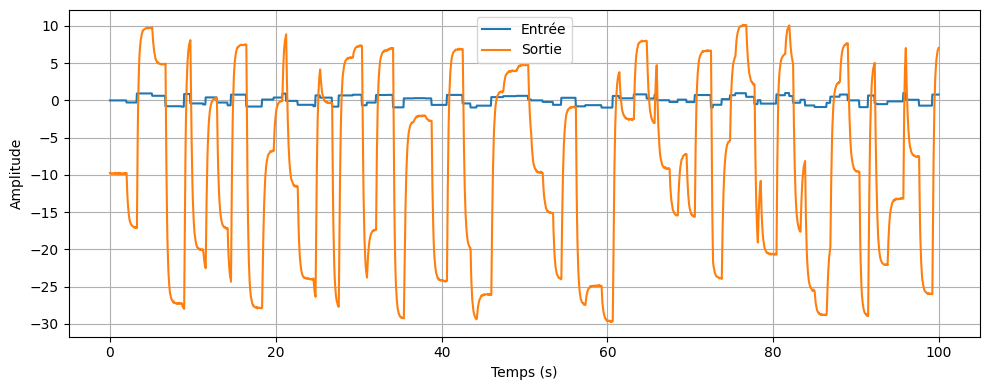

In [15]:
plot_signal(2000)

# Etape 2 : Réalisation du Modéle du systeme


In [16]:
import numpy as np
import pandas as pd
import torch
from torch import nn

# ============================================================
# 1. Paramètres
# ============================================================

BATCH_SIZE = 32
EPOCHS = 6
HIDDEN_SIZE = 64
LEARNING_RATE = 1e-3

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


Device : cpu


In [17]:
X = torch.tensor(df_in.to_numpy(dtype=np.float32))
Y = torch.tensor(df_out.to_numpy(dtype=np.float32))

if X.shape != Y.shape or X.ndim != 2 or X.shape[1] != 2000:
    raise ValueError(
        "df_in et df_out doivent avoir la même forme (N, 2000)."
    )

if not torch.isfinite(X).all() or not torch.isfinite(Y).all():
    raise ValueError("Les données contiennent des NaN ou des infinis.")

In [18]:
split = int(0.8 * len(X))

if split == 0 or split == len(X):
    raise ValueError("Il faut au moins deux signaux.")

X_train, X_test = X[:split], X[split:]
Y_train, Y_test = Y[:split], Y[split:]

print(f"Train : {len(X_train)} signaux")
print(f"Test  : {len(X_test)} signaux")

Train : 2396 signaux
Test  : 600 signaux


214990 échelons, 89.7 par signal en moyenne
niveaux : [-1.000, 1.000]
sauts   : [-1.991, 1.996]
Intervalles de niveaux avec < 1 % des paliers :


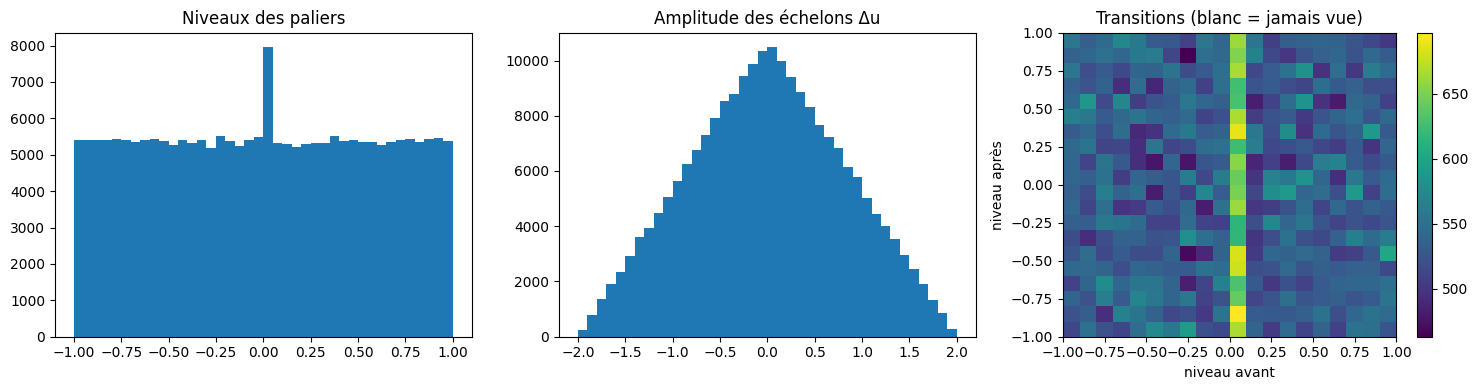

In [19]:
U = X_train                  # forme (N_signaux, T). Si tes lignes sont les instants : df_in.values.T
dU = np.diff(U, axis=1)
m = np.abs(dU) > 1e-6        # instants où un échelon a lieu

niveaux = np.concatenate([U[:, 0], U[:, 1:][m]])   # valeur de chaque palier
sauts   = dU[m]                                     # amplitude de chaque échelon
avant, apres = U[:, :-1][m], U[:, 1:][m]

print(f"{len(sauts)} échelons, {len(sauts)/len(U):.1f} par signal en moyenne")
print(f"niveaux : [{niveaux.min():.3f}, {niveaux.max():.3f}]")
print(f"sauts   : [{sauts.min():.3f}, {sauts.max():.3f}]")

# Couverture : zones vides ou peu représentées
c, b = np.histogram(niveaux, bins=20, range=(-1, 1))
print("Intervalles de niveaux avec < 1 % des paliers :")
for k in np.where(c < 0.01 * c.sum())[0]:
    print(f"  [{b[k]:.1f}, {b[k+1]:.1f}] : {c[k]}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(niveaux, bins=40, range=(-1, 1)); ax[0].set_title("Niveaux des paliers")
ax[1].hist(sauts, bins=40, range=(-2, 2));   ax[1].set_title("Amplitude des échelons Δu")
h = ax[2].hist2d(avant, apres, bins=20, range=[[-1, 1], [-1, 1]], cmin=1)
fig.colorbar(h[3], ax=ax[2]); ax[2].set_xlabel("niveau avant"); ax[2].set_ylabel("niveau après")
ax[2].set_title("Transitions (blanc = jamais vue)")
plt.tight_layout(); plt.show()

In [20]:
# ============================================================
# 4. Normalisation calculée uniquement sur l'entraînement
# ============================================================

# Une moyenne et un écart-type globaux pour les entrées
x_mean = X_train.mean()
x_std = X_train.std(unbiased=False).clamp_min(1e-8)

# Même principe pour les sorties
y_mean = Y_train.mean()
y_std = Y_train.std(unbiased=False).clamp_min(1e-8)

X_train = (X_train - x_mean) / x_std
X_test = (X_test - x_mean) / x_std

Y_train = (Y_train - y_mean) / y_std

# On garde Y_test à l'échelle d'origine pour l'évaluation finale.

In [21]:
class RNN(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x : (B, 2000)
        x = x.unsqueeze(-1)          # (B, 2000, 1)

        h_sequence, _ = self.rnn(x)  # (B, 2000, hidden_size)

        y = self.output(h_sequence)  # (B, 2000, 1)

        return y.squeeze(-1)        # (B, 2000)


model = RNN(HIDDEN_SIZE).to(device)

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [22]:
for epoch in range(EPOCHS):
    model.train()

    # Mélanger les signaux à chaque époque,
    # en conservant les correspondances entrée / sortie.
    order = torch.randperm(len(X_train))

    total_loss = 0.0

    for start in range(0, len(X_train), BATCH_SIZE):

        # Indices des signaux du batch
        idx = order[start:start + BATCH_SIZE]

        x_batch = X_train[idx].to(device)
        y_batch = Y_train[idx].to(device)

        # Effacer les gradients du batch précédent
        optimizer.zero_grad()

        # Prédictions et erreur
        predictions = model(x_batch)
        loss = loss_fn(predictions, y_batch)

        # Calcul des gradients
        loss.backward()

        # Limiter les gradients trop grands
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Mise à jour des poids
        optimizer.step()

        # Pondération par le nombre de signaux du batch
        total_loss += loss.item() * len(idx)

    train_mse = total_loss / len(X_train)

    print(
        f"Époque {epoch + 1:02d}/{EPOCHS} | "
        f"MSE train normalisée : {train_mse:.6f}"
    )


model.eval()
test_predictions = []

with torch.no_grad():

    for start in range(0, len(X_test), BATCH_SIZE):

        x_batch = X_test[start:start + BATCH_SIZE].to(device)

        predictions = model(x_batch).cpu()

        # Retour à l'échelle d'origine
        predictions = predictions * y_std + y_mean

        test_predictions.append(predictions)

pred_test = torch.cat(test_predictions, dim=0)

mse_test = ((pred_test - Y_test) ** 2).mean().item()
rmse_test = mse_test ** 0.5

print(f"MSE test  : {mse_test:.6f}")
print(f"RMSE test : {rmse_test:.6f}")


Époque 01/6 | MSE train normalisée : 0.130784
Époque 02/6 | MSE train normalisée : 0.002141
Époque 03/6 | MSE train normalisée : 0.000573
Époque 04/6 | MSE train normalisée : 0.000310
Époque 05/6 | MSE train normalisée : 0.000226
Époque 06/6 | MSE train normalisée : 0.000185
MSE test  : 0.018889
RMSE test : 0.137436


In [23]:
df_pred = pd.DataFrame(
    pred_test.numpy(),
    index=df_out.index[split:],
    columns=df_out.columns
)

In [24]:
def plot_rnn(i):    
    t =np.arange(0,2000*Ts,Ts)
    plt.plot(t,df_in.iloc[i+split])
    plt.plot(t,df_pred.iloc[i])
    plt.plot(t,df_out.iloc[i+split])


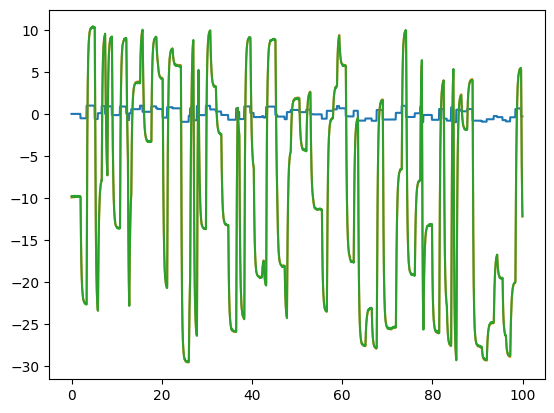

In [25]:
plot_rnn(2)

### On test avec une nouvelle entrée/sortie prise depuis simulink 

Grandeur comparée : az
RMSE : 0.0777085
MAE  : 0.0683864


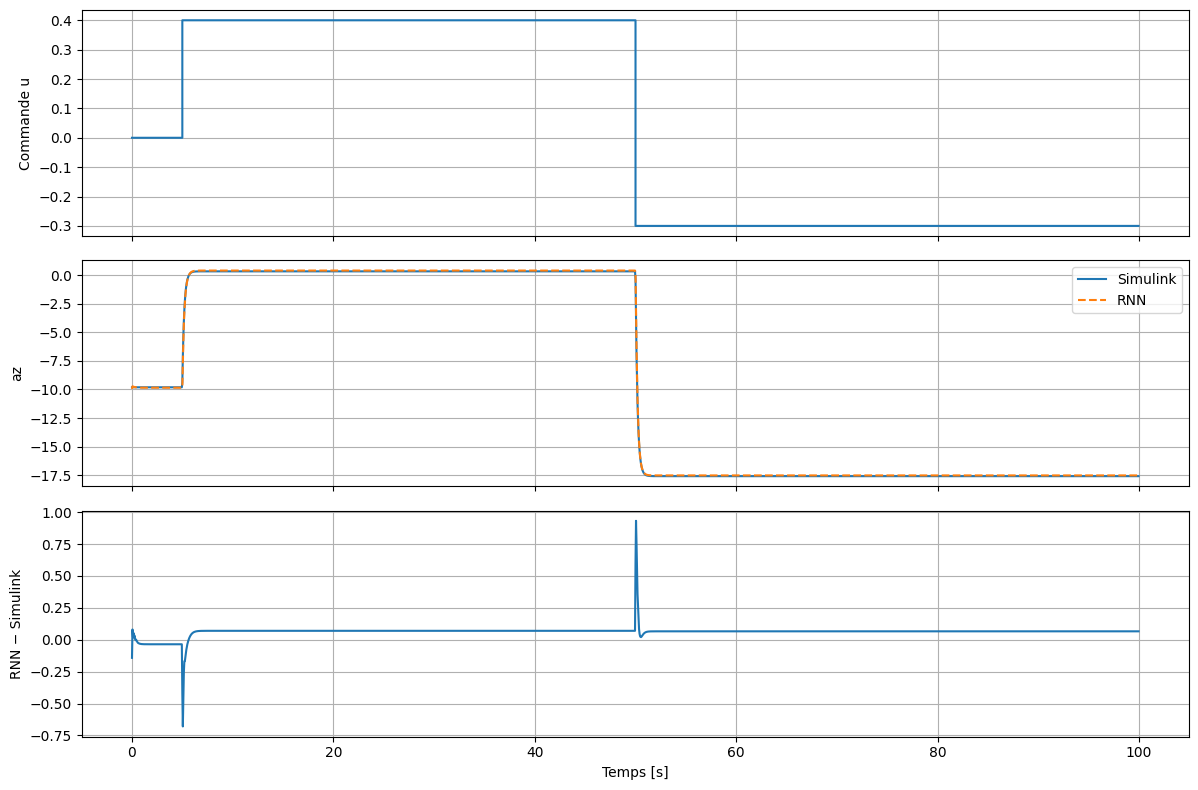

In [26]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Chargement du nouveau test
data = pd.read_csv("nouveau_test_rnn.csv")

t = data["t"].to_numpy()
u = data["u"].to_numpy(dtype=np.float32)

# IMPORTANT : choisir la grandeur réellement utilisée dans bdd_out_mat_05.csv
target = "az"   # Remplacer par "z" ou "vz" si nécessaire
y_true = data[target].to_numpy(dtype=np.float64)

assert len(u) == 2000
assert np.allclose(t, np.arange(2000) * 0.05)
assert np.isfinite(u).all()
assert np.isfinite(y_true).all()

# Valeurs de normalisation apprises pendant l'entraînement
xm = float(x_mean.detach().cpu())
xs = float(x_std.detach().cpu())
ym = float(y_mean.detach().cpu())
ys = float(y_std.detach().cpu())

# Même appareil et même type numérique que le réseau
parameter = next(model.parameters())

# Une séquence de 2000 points : forme (1, 2000)
x_new = torch.as_tensor(
    u.reshape(1, -1),
    dtype=parameter.dtype,
    device=parameter.device,
)

# Normalisation des entrées avec les statistiques D'ENTRAÎNEMENT
x_new = (x_new - xm) / xs

# Prédiction
model.eval()

with torch.no_grad():
    y_standardized = model(x_new).cpu().numpy()

# Inversion de la deuxième normalisation
y_minmax = y_standardized * ys + ym

# Inversion de la première normalisation : retour aux unités physiques
y_pred = y_minmax.astype(np.float64).ravel()      # la sortie est déjà a_z en m/s²

# Mesures d'erreur en unités physiques
error = y_pred - y_true

rmse = np.sqrt(np.mean(error**2))
mae = np.mean(np.abs(error))

print(f"Grandeur comparée : {target}")
print(f"RMSE : {rmse:.6g}")
print(f"MAE  : {mae:.6g}")

# Comparaison graphique
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].step(t, u, where="post")
axes[0].set_ylabel("Commande u")
axes[0].grid(True)

axes[1].plot(t, y_true, label="Simulink")
axes[1].plot(t, y_pred, "--", label="RNN")
axes[1].set_ylabel(target)
axes[1].legend()
axes[1].grid(True)

axes[2].plot(t, error)
axes[2].set_ylabel("RNN − Simulink")
axes[2].set_xlabel("Temps [s]")
axes[2].grid(True)

plt.tight_layout()
plt.show()

#### On enregistre les poids de notre RNN 


In [27]:
%pip install gymnasium stable-baselines3 scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\johar\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [30]:
sd = {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}
np.savez("rnn_plant.npz",
        W_ih=sd["rnn.weight_ih_l0"], W_hh=sd["rnn.weight_hh_l0"],
        b_ih=sd["rnn.bias_ih_l0"],   b_hh=sd["rnn.bias_hh_l0"],
        W_out=sd["output.weight"],   b_out=sd["output.bias"],
        x_mean=float(x_mean), x_std=float(x_std), y_mean=float(y_mean), y_std=float(y_std),
        mm_scale=np.array(1.0), mm_min=np.array(0.0))